In [1]:
import os
import json

import pandas as pd
import numpy as np
from scipy.stats import entropy
import random
import matplotlib.pyplot as plt
import seaborn as sns
from cluster_weather_years.functions import build_df, standardize_df
from cluster_weather_years.constants import (
    BASE_OUTPUT,
    MODELS,
    YEARS,
    NUM_CLUSTERS,
)

# 1. Build dataframes

In [12]:
# build df
DF_PROD_DEMAND_FNAME = os.path.join(BASE_OUTPUT, "dataframes/df_prod_demand_daily.csv")
OUTPUT_DIR = os.path.join(BASE_OUTPUT, "simulated_annealing")

vars_to_standardize = ["NL_OFF_prod", "NL_ON_prod", "NL_SOLAR_prod", "Demand"]
df_daily = pd.read_csv(DF_PROD_DEMAND_FNAME, index_col=0)
df_daily["Date"] = pd.to_datetime(df_daily["Date"])
df_std = standardize_df(df_daily, vars_to_standardize)

In [3]:
selection = json.load(open(os.path.join(OUTPUT_DIR, "energy_selected_full_sa_cost_2.0_0.98_5000_0.json")))
selected = selection["selected"]

In [4]:
# random draw of NUM_CLUSTER years for comparison
random_models = random.choices(MODELS, k=NUM_CLUSTERS)
random_years = random.choices(YEARS, k=NUM_CLUSTERS)

# build df with daily data of selected years
frames_centroids = []
frames_random = []
for i, (model, year) in enumerate(selected):
    # model_centroid, year_centroid = row["model"], row["Date"]
    model_random, year_random = random_models[i], random_years[i]
    df_centroid = df_daily.query(f"model == '{model}' and year == {year}")
    df_random = df_daily.query(f"model == '{model_random}' and year == {year_random}")
    frames_centroids.append(df_centroid)
    frames_random.append(df_random)

df_centroids = pd.concat(frames_centroids, ignore_index=True)
df_random = pd.concat(frames_random, ignore_index=True)

# 2. Perform comparison

In [5]:
# just simple ECDF plots for visual inspection
def ecdf_comparison(df_daily, df_centroids, df_random, columns):
    fig, axs = plt.subplots(2, 2, figsize=(12, 10), sharey=True)

    for i, col in enumerate(columns):
        ax = axs.flat[i]
        sns.ecdfplot(df_centroids, x=col, label="Centroid years", ax=ax)
        sns.ecdfplot(df_random, x=col, label="Randomly sampled years", ax=ax)
        sns.ecdfplot(df_daily, x=col, label="Full climatology", ax=ax)
        ax.set_title(col)
        ax.set_ylim(0, 1.02)
        ax.legend(loc="lower right")

    # Hide any unused axes (in case columns < 4)
    for j in range(len(columns), 4):
        axs.flat[j].axis("off")

In [6]:
def qq_comparison(df_daily, df_centroids, df_random, columns):
    # Quantile comparison: invert ECDFs and compare
    dense = np.linspace(0.005, 0.05, 100, endpoint=False)
    coarse = np.linspace(0.05, 0.995, 96)
    probs = np.concatenate([dense, coarse])

    # Container for metrics rows
    metrics_rows = []

    # Prepare figures: QQ plots and quantile differences
    fig_qq, axs_qq = plt.subplots(2, 2, figsize=(12, 10))
    fig_diff, axs_diff = plt.subplots(2, 2, figsize=(12, 10), sharey=False)

    for i, col in enumerate(columns):
        # Compute quantiles at common probabilities
        q_full = df_daily[col].quantile(probs)
        q_cent = df_centroids[col].quantile(probs)
        q_rand = df_random[col].quantile(probs)

        # Compute weights for MAE calculation
        w = np.empty_like(probs)
        w[1:-1] = (probs[2:] - probs[:-2]) / 2
        w[0] = (probs[1] - probs[0]) / 2
        w[-1] = (probs[-1] - probs[-2]) / 2


        # Metrics vs full
        diff_cent = (q_cent - q_full).values
        diff_rand = (q_rand - q_full).values

        mae_cent = np.average(np.abs(diff_cent), weights=w)
        mae_rand = np.average(np.abs(diff_rand), weights=w)

        rmse_cent = np.sqrt(np.average(diff_cent**2, weights=w))
        rmse_rand = np.sqrt(np.average(diff_rand**2, weights=w))
        
        maxabs_cent = np.max(np.abs(diff_cent))
        maxabs_rand = np.max(np.abs(diff_rand))

        metrics_rows.append({
            "variable": col,
            "subset": "Centroid",
            "MAE": mae_cent,
            "RMSE": rmse_cent,
            "MaxAbs": maxabs_cent,
        })
        metrics_rows.append({
            "variable": col,
            "subset": "Random",
            "MAE": mae_rand,
            "RMSE": rmse_rand,
            "MaxAbs": maxabs_rand,
        })

        # QQ plot: y(subset) vs x(full)
        axq = axs_qq.flat[i]
        x = q_full.values
        axq.plot(x, q_cent.values, label="Centroid years")
        axq.plot(x, q_rand.values, label="Random years")
        # 45-degree line
        lo, hi = np.nanmin(x), np.nanmax(x)
        axq.plot([lo, hi], [lo, hi], "k--", lw=1, label="y=x")
        axq.set_title(f"QQ: {col}")
        axq.set_xlabel("Full climatology quantile")
        axq.set_ylabel("Subset quantile")
        axq.legend(loc="best")

        # Quantile differences vs probability
        axd = axs_diff.flat[i]
        axd.plot(probs, diff_cent, c= 'C0', label="Centroid - Full")
        axd.plot(probs, diff_rand, c= 'C1', label="Random - Full")
        axd.plot(probs, np.abs(diff_cent), c= 'C0', ls='--')
        axd.plot(probs, np.abs(diff_rand), c= 'C1', ls='--')
        axd.axhline(0.0, color="k", lw=1, ls="--")
        axd.set_title(f"Δ quantile vs p: {col}")
        axd.set_xlabel("Probability p")
        axd.set_ylabel("Δ quantile")
        axd.legend(loc="best")

    # Hide any unused axes (in case fewer than 4 columns)
    for j in range(len(columns), 4):
        axs_qq.flat[j].axis("off")
        axs_diff.flat[j].axis("off")

    fig_qq.tight_layout()
    fig_diff.tight_layout()

    metrics_df = pd.DataFrame(metrics_rows)
    return metrics_df


,variable,subset,MAE,RMSE,MaxAbs
0,Residual_load,Centroid,2.587617,3.521790,17.348837
1,Residual_load,Random,8.409834,10.487945,22.970562
2,NL_ON_prod,Centroid,0.975544,1.285595,3.438082
3,NL_ON_prod,Random,1.310285,1.618892,3.792273
4,NL_SOLAR_prod,Centroid,1.891568,2.395955,5.906723
5,NL_SOLAR_prod,Random,3.820150,4.968394,14.083185
6,Demand,Centroid,0.881309,1.296662,4.254069
7,Demand,Random,4.783625,6.281974,16.165968


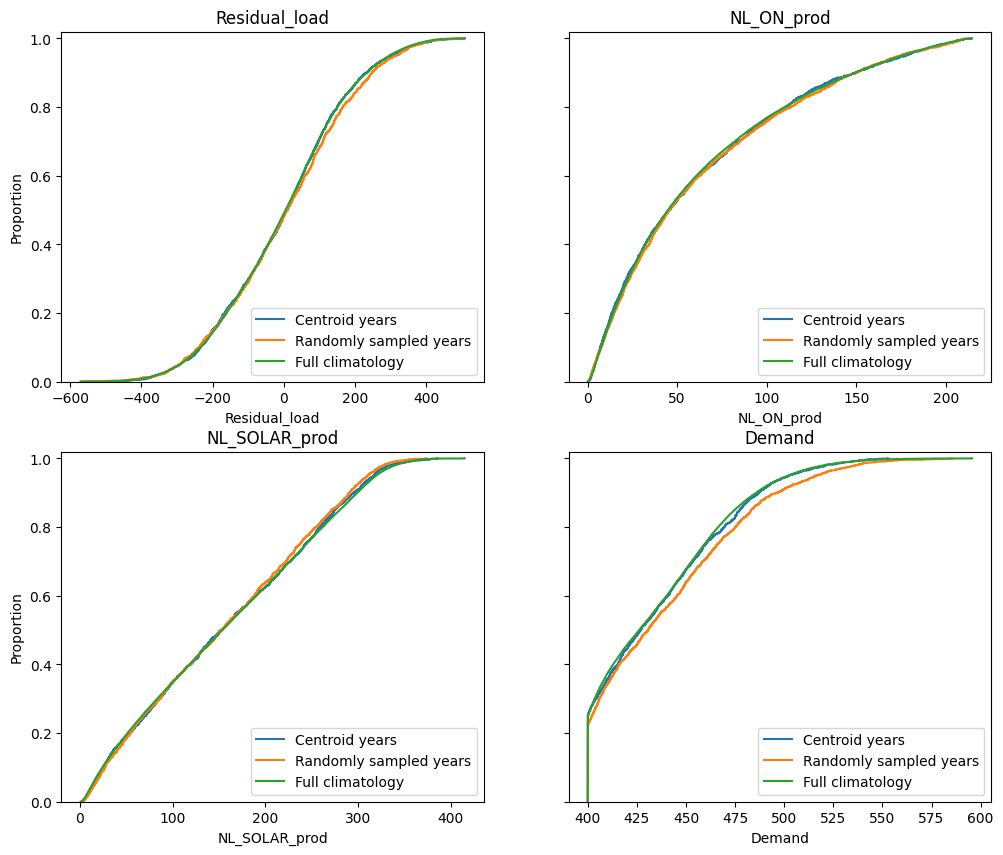

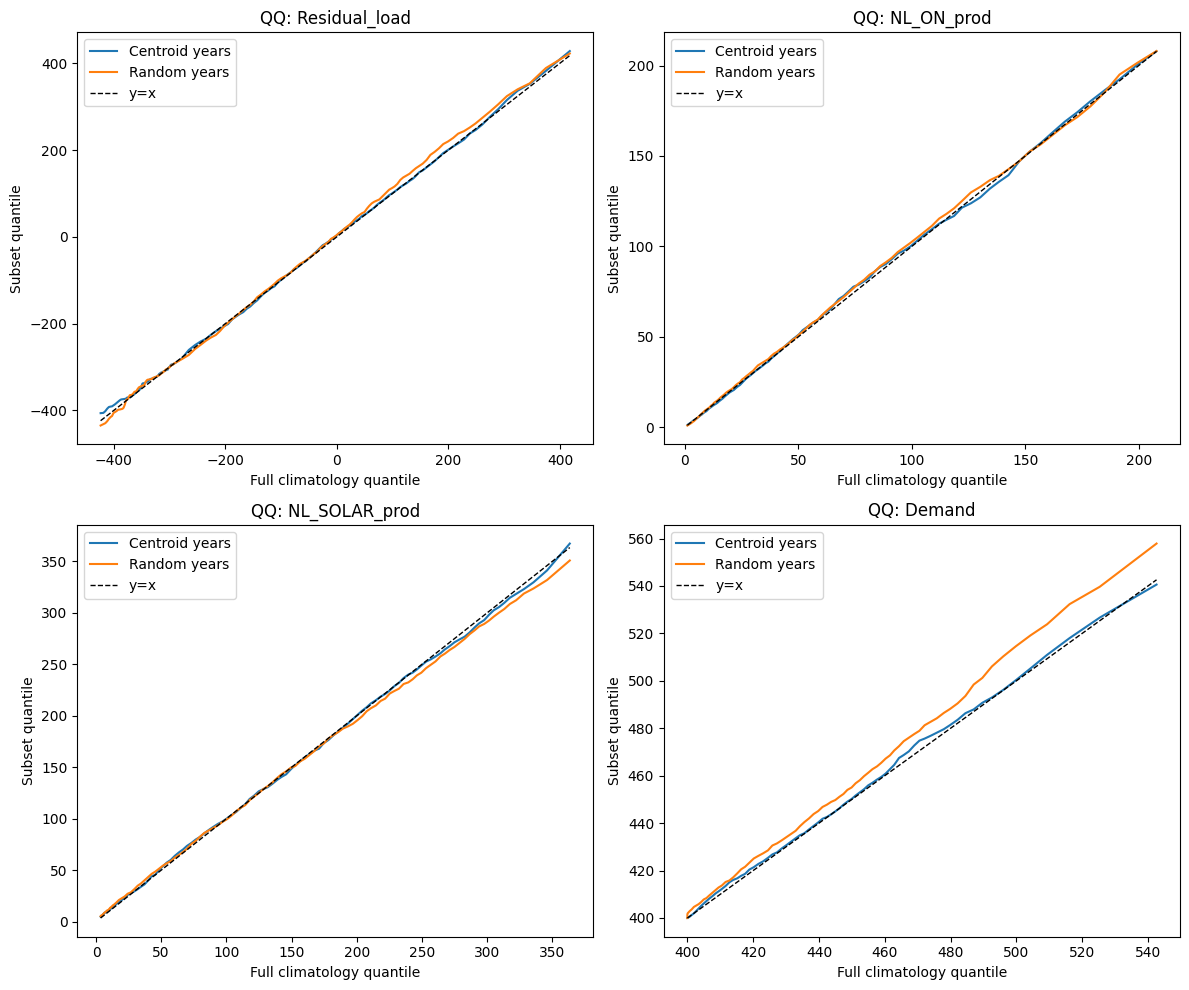

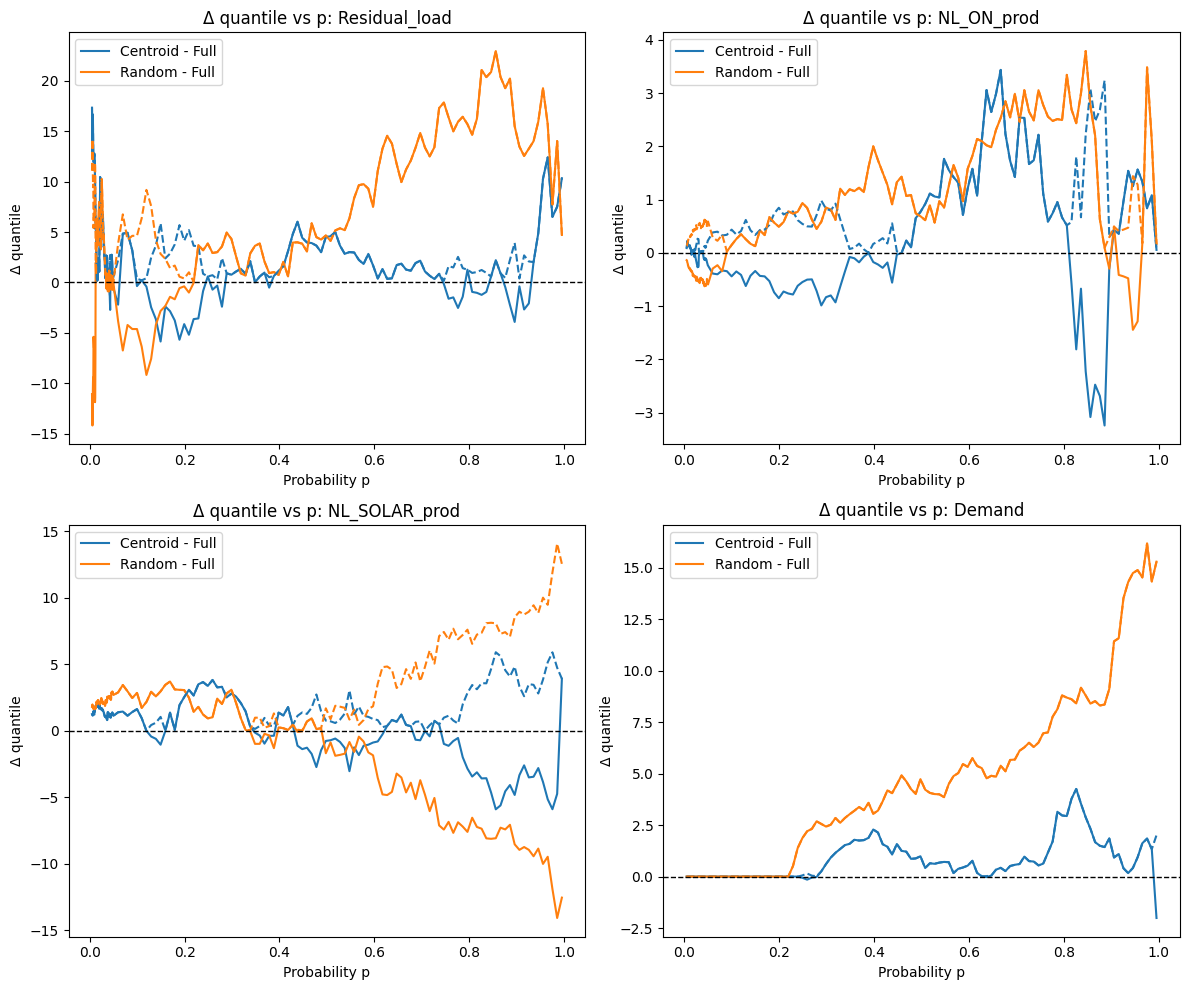

In [7]:
columns = ["Residual_load", "NL_ON_prod", "NL_SOLAR_prod", "Demand"]
ecdf_comparison(df_daily, df_centroids, df_random, columns)
qq_comparison(df_daily, df_centroids, df_random, columns)

# 3. Look at longer-events (non-optimized)

,variable,subset,MAE,RMSE,MaxAbs
0,Residual_load,Centroid,5.432663,9.859307,54.152025
1,Residual_load,Random,9.003513,10.415606,29.957696
2,NL_ON_prod,Centroid,1.093913,1.224267,2.676560
3,NL_ON_prod,Random,2.984942,3.537962,10.258352
4,NL_SOLAR_prod,Centroid,1.743734,2.687261,18.453818
5,NL_SOLAR_prod,Random,2.697058,3.815516,10.035779
6,Demand,Centroid,1.169107,1.509308,4.930535
7,Demand,Random,4.728917,6.277183,21.929417


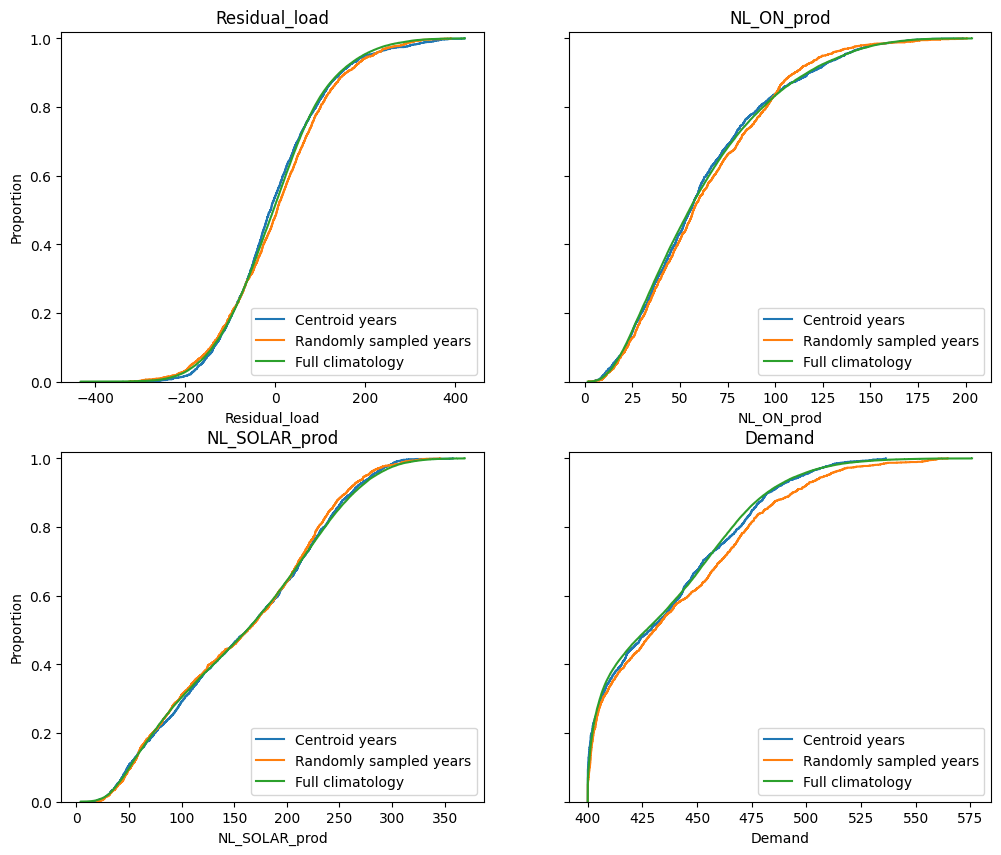

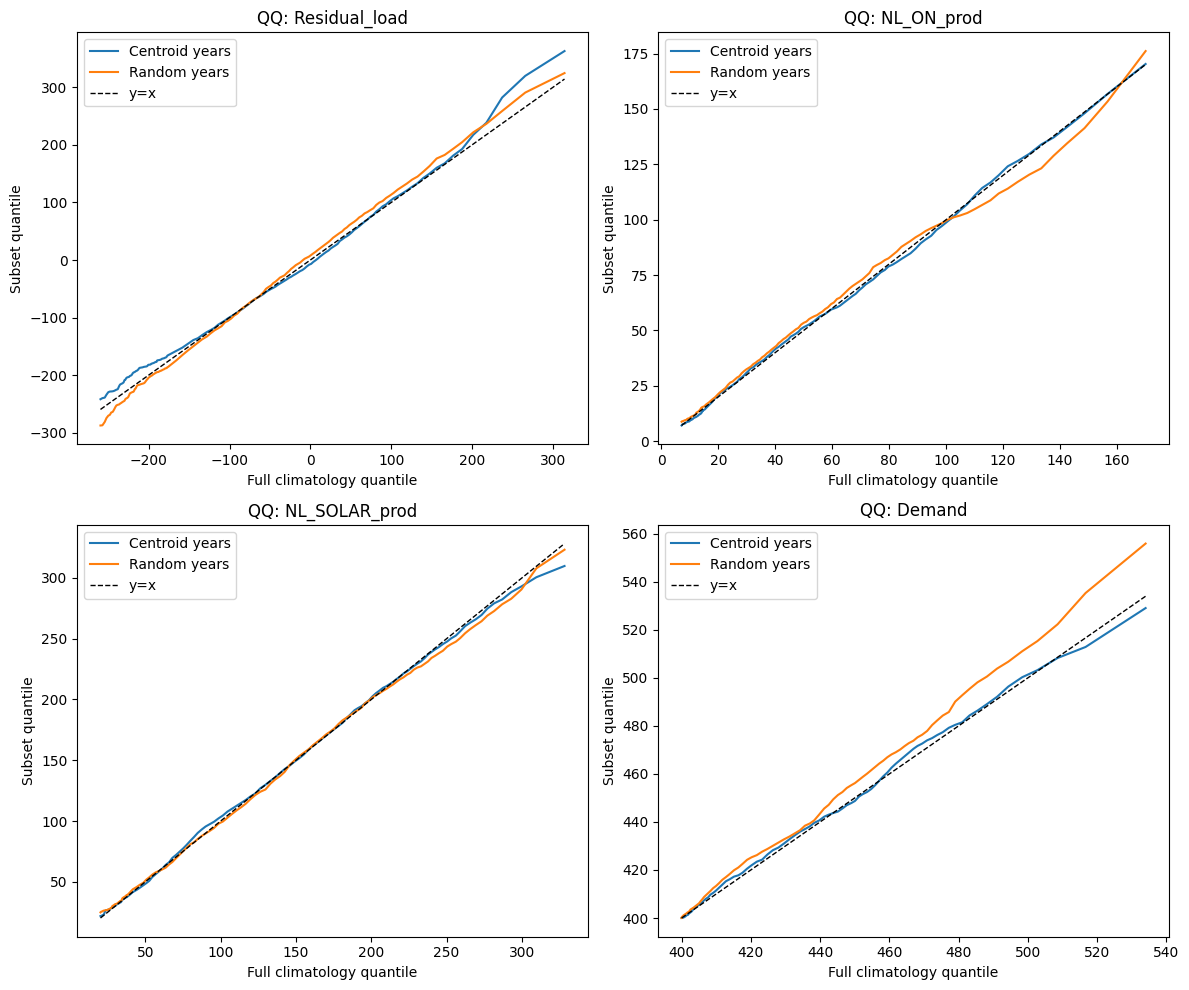

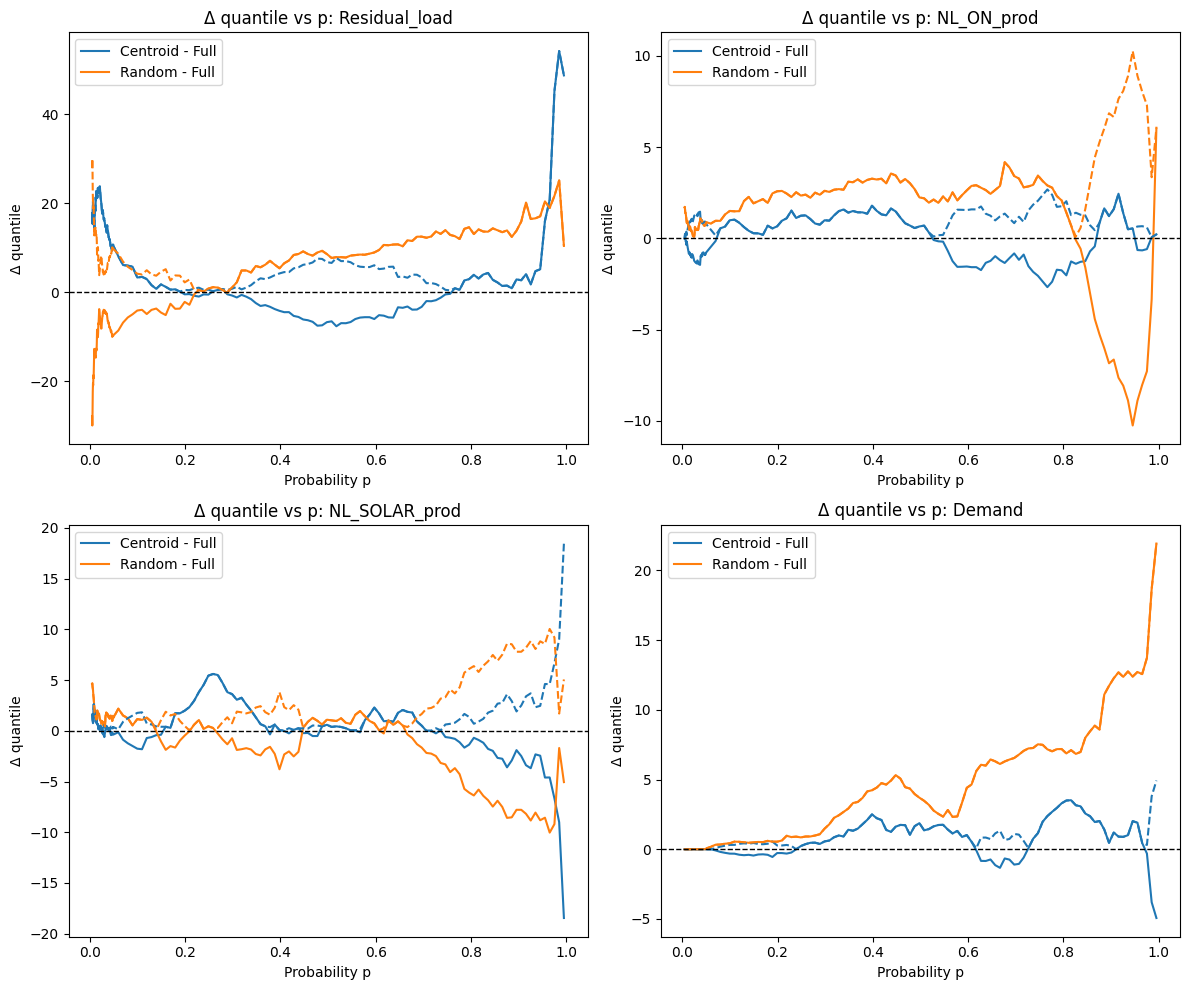

In [8]:
ecdf_comparison(df_daily[columns].rolling(window=7).mean(), df_centroids[columns].rolling(window=7).mean(), df_random[columns].rolling(window=7).mean(), columns)
qq_comparison(df_daily[columns].rolling(window=7).mean(), df_centroids[columns].rolling(window=7).mean(), df_random[columns].rolling(window=7).mean(), columns)

In [14]:
df_daily["Residual_rolling7"] = df_daily['Residual_load'].rolling(window=7).mean()

In [ ]:
df_centroid

,model,Date,year,Demand,NL_OFF_prod,NL_ON_prod,NL_SOLAR_prod,Residual_load
49676,mpi_esm1_2_hr,2031-01-01,2031,472.895355,271.071038,112.321923,26.7228,62.779593
49677,mpi_esm1_2_hr,2031-01-02,2031,482.052122,318.133206,104.899219,17.1324,41.887296
49678,mpi_esm1_2_hr,2031-01-03,2031,507.877814,436.613368,143.331540,26.6946,-98.761694
49679,mpi_esm1_2_hr,2031-01-04,2031,526.646220,402.848112,116.680968,132.9468,-125.829661
49680,mpi_esm1_2_hr,2031-01-05,2031,529.626913,287.008002,51.606940,24.5574,166.454571
...,...,...,...,...,...,...,...,...
50036,mpi_esm1_2_hr,2031-12-27,2031,488.285549,436.243141,187.950823,84.8592,-220.767615
50037,mpi_esm1_2_hr,2031-12-28,2031,479.666221,312.806256,74.337452,29.4870,63.035513
50038,mpi_esm1_2_hr,2031-12-29,2031,463.776113,356.573601,121.755863,113.9220,-128.475351
50039,mpi_esm1_2_hr,2031-12-30,2031,452.326076,440.237119,208.142551,33.0354,-229.088994


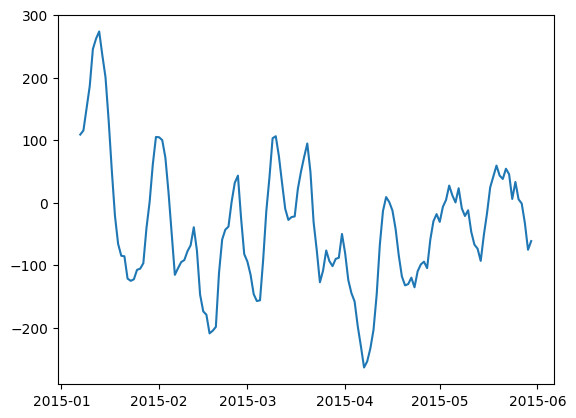

In [15]:
plt.plot(df_daily["Date"][:150], df_daily["Residual_rolling7"][:150])

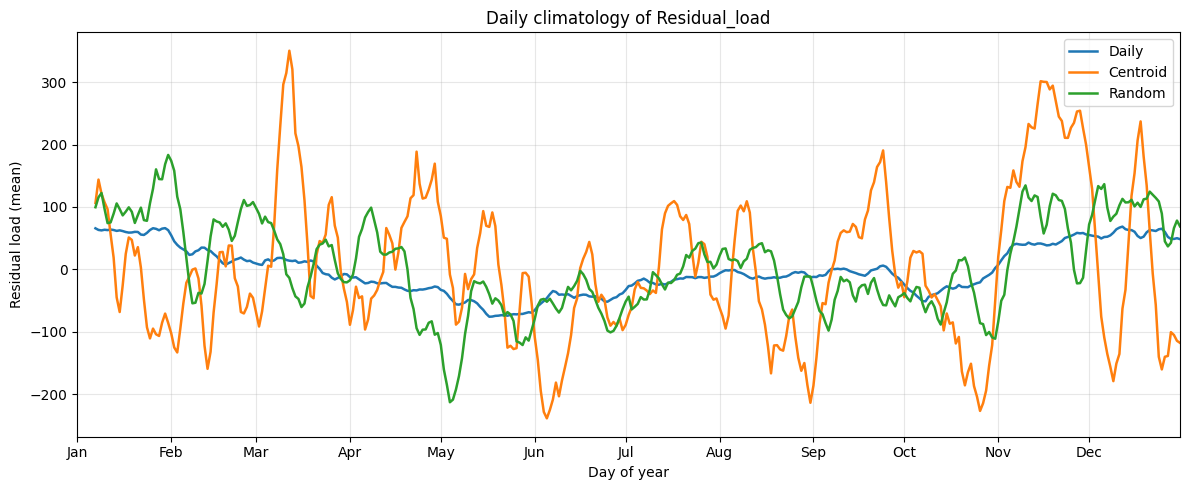

In [24]:
_d = df_daily.copy()
_d["Date"] = pd.to_datetime(_d["Date"], errors="coerce")
_doy = pd.to_datetime(_d["Date"].dt.strftime("2001-%m-%d"), errors="coerce").dt.dayofyear
clim_daily = (
    _d.assign(doy=_doy)
    .dropna(subset=["doy", "Residual_load"])  # drops Feb 29 + invalid rows
    .groupby("doy")["Residual_load"].mean()
)

_c = df_centroid.copy()
_c["Date"] = pd.to_datetime(_c["Date"], errors="coerce")
_coy = pd.to_datetime(_c["Date"].dt.strftime("2001-%m-%d"), errors="coerce").dt.dayofyear
clim_centroid = (
    _c.assign(doy=_coy)
    .dropna(subset=["doy", "Residual_load"])  # drops Feb 29 + invalid rows
    .groupby("doy")["Residual_load"].mean()
)

_r = df_random.copy()
_r["Date"] = pd.to_datetime(_r["Date"], errors="coerce")
_roy = pd.to_datetime(_r["Date"].dt.strftime("2001-%m-%d"), errors="coerce").dt.dayofyear
clim_random = (
    _r.assign(doy=_roy)
    .dropna(subset=["doy", "Residual_load"])  # drops Feb 29 + invalid rows
    .groupby("doy")["Residual_load"].mean()
)

climatology_df = pd.concat(
    [
        clim_daily.rename("Daily"),
        clim_centroid.rename("Centroid"),
        clim_random.rename("Random"),
    ],
    axis=1,
)

plt.figure(figsize=(12, 5))
for col in ["Daily", "Centroid", "Random"]:
    plt.plot(climatology_df.index, climatology_df[col].rolling(window=7).mean(), label=col, lw=1.8)


month_starts = pd.date_range("2001-01-01", "2001-12-01", freq="MS")
plt.xticks([d.dayofyear for d in month_starts], [d.strftime("%b") for d in month_starts])

plt.xlim(1, 365)
plt.xlabel("Day of year")
plt.ylabel("Residual load (mean)")
plt.title("Daily climatology of Residual_load")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

